# 06 · Extension: how much does the liquidity floor matter?

The main results (02–05) trade only coins with a trailing 30-day mean daily volume of at least
**$20m**. Lower floors let in thin coins whose funding is far more extreme and whose squeezes are
far larger - bigger numbers, driven by fewer, wilder days. This notebook shows how the two books
change with the floor, and whether a small account (≤ $10k) could even trade the thin coins.

In [1]:
# run from the project root (works from research/ or any subfolder); the strategy package is
# in src/, the data download and plot style in research/lib
import os, sys
while not os.path.isdir("config") and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir("..")
sys.path[:0] = [os.path.abspath("src"), os.path.abspath("research/lib")]

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from betafunding import *
from plotstyle import *
apply()
cfg = load_config()
panel = load_panel(**cfg["data"])
BM, START = cfg["benchmarks"], cfg["backtest"]["start"]
FLOORS = [1e5, 1e6, 5e6, 1e7, 2e7, 5e7]
name = lambda f: f"${f/1e6:g}m"
BOOKS = {"as specified": ORIGINAL_SPEC, "improved": {}}   # improved = the final strategy (cfg)
runs, rows = {}, {}
for b, ov in BOOKS.items():
    for f in FLOORS:
        c = override(cfg, {**ov, "risk.min_dollar_volume": f})
        s = build_signals(panel, c)
        r = run(panel, s, c, START)
        runs[(b, f)] = (r, s)
        rows[(b, name(f))] = summarize(r.daily, panel, BM, r.weights)
res = pd.DataFrame(rows).T
res[["net_apy_%", "funding_apy_%", "price_apy_%", "sharpe", "ex_best10_%", "median_month_%",
     "max_dd_compound_%", "worst_day_%", "avg_n_long", "avg_n_short"]].astype(float).round(2)

net_apy_%  funding_apy_%  price_apy_%  sharpe  \
as specified $0.1m     159.48         284.57      -107.03    1.27   
             $1m       163.46         286.15      -104.18    1.26   
             $5m       113.37         280.75      -150.27    1.31   
             $10m      110.68         261.25      -136.54    1.31   
             $20m      114.11         209.89       -85.53    1.62   
             $50m       61.48         116.18       -50.07    1.27   
improved     $0.1m     157.69         143.67        22.54    1.93   
             $1m       157.69         143.67        22.54    1.93   
             $5m       112.00         137.14       -17.54    2.11   
             $10m       99.05         129.78       -24.17    1.95   
             $20m       80.59         110.15       -24.53    1.87   
             $50m       54.18          73.13       -16.18    1.62   

                    ex_best10_%  median_month_%  max_dd_compound_%  \
as specified $0.1m        44.57            2.18             -62.27   
             $1m          45.59            2.04             -61.96   
             $5m          50.12            0.85             -71.31   
             $10m         40.54            0.58             -52.56   
             $20m         96.60            4.69             -62.46   
             $50m          4.46            4.08             -28.27   
improved     $0.1m       158.33            7.45             -31.49   
             $1m         158.33            7.45             -31.49   
             $5m         121.40            1.37             -36.78   
             $10m         95.06            1.37             -38.16   
             $20m         67.51            1.29             -22.95   
             $50m         26.23            1.10             -17.72   

                    worst_day_%  avg_n_long  avg_n_short  
as specified $0.1m       -24.83       27.81        66.28  
             $1m         -23.35       27.35        65.44  
             $5m         -18.56       26.32        40.05  
             $10m        -24.83       23.06        30.25  
             $20m        -20.75       18.84        21.12  
             $50m        -12.63       10.80        11.82  
improved     $0.1m       -17.46        3.12         1.75  
             $1m         -17.46        3.12         1.75  
             $5m         -17.02        2.98         1.68  
             $10m        -15.80        2.90         1.61  
             $20m        -13.21        2.65         1.51  
             $50m        -11.68        2.15         1.43

## How the results move with the floor

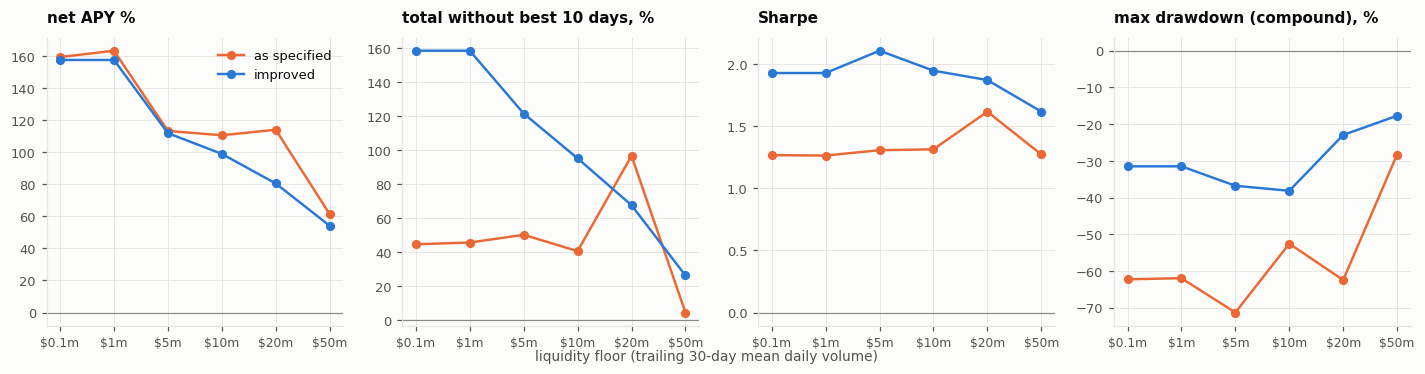

In [3]:
ramp = ["#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]   # one hue, light = thin coins
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (col, lab) in zip(axes, [("net_apy_%", "net APY %"), ("ex_best10_%", "total without best 10 days, %"),
                                 ("sharpe", "Sharpe"), ("max_dd_compound_%", "max drawdown (compound), %")]):
    for b, c in zip(BOOKS, (SERIES[1], SERIES[0])):
        y = res.loc[b, col].astype(float)
        ax.plot(range(len(y)), y.values, "o-", color=c, ms=5, label=b)
    ax.set_xticks(range(len(FLOORS)), [name(f) for f in FLOORS], fontsize=8); ax.set_title(lab, fontsize=10)
    zero(ax)
axes[0].legend(loc="upper right"); fig.supxlabel("liquidity floor (trailing 30-day mean daily volume)", fontsize=9, color=INK2)
save(fig, "ext_liquidity_metrics"); plt.show()

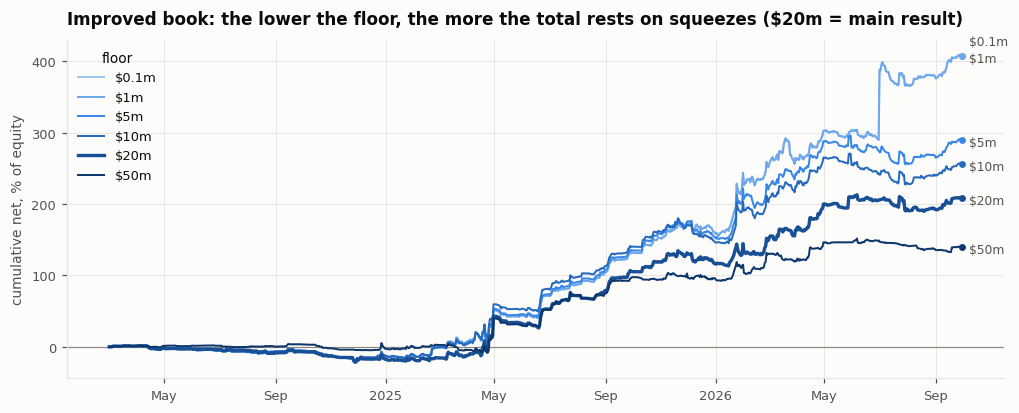

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
for f, c in zip(FLOORS, ramp):
    y = runs[("improved", f)][0].daily["net"].cumsum() * 100
    ax.plot(y.index, y, color=c, lw=2.2 if f == 2e7 else 1.3, label=name(f)); end_label(ax, y, name(f), c)
zero(ax); ax.set_ylabel("cumulative net, % of equity"); ax.legend(title="floor", loc="upper left")
ax.set_title("Improved book: the lower the floor, the more the total rests on squeezes ($20m = main result)")
save(fig, "ext_liquidity_equity"); plt.show()

## How many coins each floor leaves, and could a $10k account trade them?

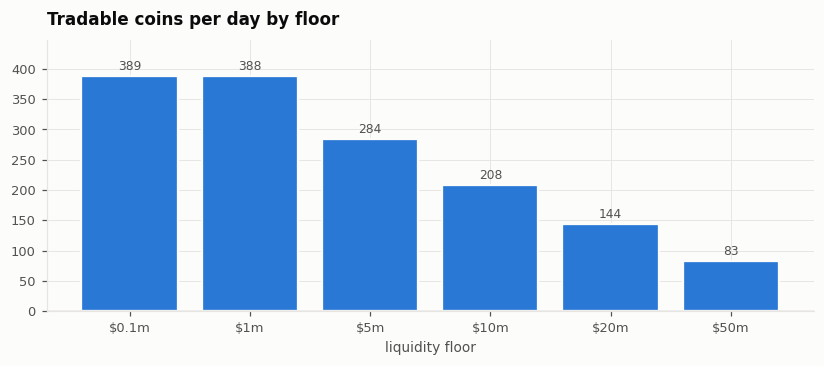

,tradable coins / day (median),"position / daily volume, median %","position / daily volume, 95th pct %","position / daily volume, max %"
$0.1m,389.0,0.0008,0.0129,0.1510
$1m,388.0,0.0008,0.0129,0.1510
$5m,284.5,0.0007,0.0097,0.1661
$10m,208.0,0.0006,0.0081,0.1503
$20m,144.5,0.0006,0.0069,0.0513
$50m,83.0,0.0004,0.0043,0.0132


In [5]:
EQ = 10_000
rows = {}
for f in FLOORS:
    r, s = runs[("improved", f)]
    W = r.weights.drop(columns=[x for x in BM if x in r.weights])
    dv = panel.dollar_volume.shift(1).reindex(index=W.index, columns=W.columns)
    part = ((W.abs() * EQ).where(W != 0) / dv.where(dv > 0)).stack() * 100
    rows[name(f)] = {"tradable coins / day (median)": s.eligible.sum(axis=1).median(),
                     "position / daily volume, median %": part.median(),
                     "position / daily volume, 95th pct %": part.quantile(.95),
                     "position / daily volume, max %": part.max()}
cap = pd.DataFrame(rows).T
fig, ax = plt.subplots(figsize=(9, 3.2))
bars(ax, cap["tradable coins / day (median)"], fmt="{:.0f}")
ax.set_title("Tradable coins per day by floor"); ax.set_xlabel("liquidity floor")
save(fig, "ext_liquidity_universe"); plt.show()
cap.round(4)

## Findings

- **Lower floor, bigger numbers**: the final book (20% cap) makes +158% APY at a $100k floor, +81% at $20m, +54% at $50m; the as-specified book +159% / +114% / +61%.
- **Sharpe** of the final book: 1.93 at $100k, 2.11 at $5m, 1.95 at $10m, 1.87 at $20m, 1.62 at $50m - fairly flat between $100k and $20m. **Drawdown** is smallest at $20m and above (−23%, $50m −18%) versus −31% to −38% for $100k – $10m.
- The final book beats the as-specified book at every floor on Sharpe and drawdown.
- **Capacity is not the constraint for a ≤ $10k account**: at any floor the 95th percentile position is under 0.02% of the coin's daily volume.